## Extracao dos dados

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold
import numpy as np
import seaborn as sns
from scipy import stats
import json
import subprocess
import joblib
from pathlib import Path

PROJETO_RAIZ = next(
    diretorio for diretorio in [Path.cwd(), *Path.cwd().parents]
    if (diretorio / "pyproject.toml").exists()
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
    precision_score, recall_score, f1_score, roc_curve, roc_auc_score
)
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

pd.set_option("display.max_columns", None)

## Funcoes do pipeline


In [2]:
def carregar_base(caminho, separador=","):
    return pd.read_csv(caminho, sep=separador)

def renomear_colunas(df, mapa):
    return df.rename(columns=mapa)

def mapear_colunas(df, mapas):
    df = df.copy()
    for coluna, mapa in mapas.items():
        df[coluna] = df[coluna].map(mapa)
    return df

def remover_colunas(df, colunas):
    return df.drop(columns=list(colunas))

def aplicar_one_hot(df, especificacoes):
    df = df.copy()
    dummies = []
    colunas_remover = []
    for coluna, mapa, prefixo in especificacoes:
        codificado = pd.get_dummies(df[coluna].map(mapa), prefix=prefixo).astype(int)
        dummies.append(codificado)
        colunas_remover.append(coluna)
    return pd.concat([df.drop(columns=colunas_remover), *dummies], axis=1)

def exibir_estrutura(df):
    df.info()
    return df.shape[0]

def diagnosticar_ausentes(df):
    print(df.isna().sum())
    return df[
        (df["meses_como_cliente"].isna())
        | (df["meses_como_cliente"] == 0)
    ]

def remover_clientes_sem_cobranca(df, quantidade_registros_iniciais):
    meses_como_cliente_igual_a_zero = df["meses_como_cliente"] == 0
    total_cobrado_numerico = pd.to_numeric(df["total_cobrado_durante_trimestre"], errors="coerce")
    total_cobrado_nulo_vazio_ou_zero = total_cobrado_numerico.isna() | (total_cobrado_numerico == 0)
    df = df[~(meses_como_cliente_igual_a_zero & total_cobrado_nulo_vazio_ou_zero)].copy()
    soma_de_registros_atuais = df.shape[0]
    print(f"Registros iniciais: {quantidade_registros_iniciais}, Registros atuais: {soma_de_registros_atuais}, Registros removidos: {quantidade_registros_iniciais - soma_de_registros_atuais}")
    df["total_cobrado_durante_trimestre"] = df["total_cobrado_durante_trimestre"].astype("float64")
    return df

def contar_addons(df, colunas, nome_coluna):
    df = df.copy()
    df[nome_coluna] = df[colunas].sum(axis=1)
    return df

def remover_duplicatas(df):
    soma_de_registros_antes_da_deduplicacao = df.shape[0]
    quantidade_de_duplicatas = df.duplicated().sum()
    print(f"Linhas duplicadas encontradas: {quantidade_de_duplicatas}")
    df = df.drop_duplicates()
    soma_de_registros_depois_da_deduplicacao = df.shape[0]
    print(f"Registros antes: {soma_de_registros_antes_da_deduplicacao}, Registros depois: {soma_de_registros_depois_da_deduplicacao}, Registros removidos: {soma_de_registros_antes_da_deduplicacao - soma_de_registros_depois_da_deduplicacao}")
    return df

def exibir_proporcao_target(df, textos_desbalanceado, texto_balanceado, coluna="target"):
    print("=== DISTRIBUICAO DA VARIAVEL TARGET ===\n")
    target_counts = df[coluna].value_counts()
    target_percentages = df[coluna].value_counts(normalize=True) * 100

    print("Contagem:")
    print(target_counts)
    print("\nPercentual:")
    for idx, pct in target_percentages.items():
        label = "Nao cancelou" if idx == 0 else "Cancelou"
        print(f"{label} ({idx}): {pct:.2f}%")

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].bar(['Nao cancelou', 'Cancelou'], target_counts.values, color=['lightblue', 'coral'])
    axes[0].set_ylabel('Frequencia')
    axes[0].set_title('Distribuicao da Variavel Target')
    axes[0].grid(axis='y', alpha=0.3)

    axes[1].pie(target_counts.values, labels=['Nao cancelou', 'Cancelou'],
                autopct='%1.1f%%', colors=['lightblue', 'coral'], startangle=90)
    axes[1].set_title('Proporcao de Classes')

    plt.tight_layout()
    plt.show()

    ratio = target_counts.min() / target_counts.max()
    print(f"\nRatio de balanceamento: {ratio:.2f}")
    if ratio < 0.5:
        for texto in textos_desbalanceado:
            print(texto)
    else:
        print(texto_balanceado)

def descrever_colunas(df, colunas):
    return df[list(colunas)].describe().round(2)

def exibir_dispersao(df, colunas):
    n = len(colunas)
    ncols = 3
    nrows = int(np.ceil(n / ncols))

    fig, axes = plt.subplots(nrows, ncols, figsize=(12, 4 * nrows))
    axes = axes.ravel()

    for idx, col in enumerate(colunas):
        sns.boxplot(x=df[col], ax=axes[idx], color='coral')
        axes[idx].set_title(f'Boxplot: {col}', fontweight='bold')
        axes[idx].set_xlabel(col)
        axes[idx].grid(axis='x', alpha=0.3)

        col_zscore = np.abs(stats.zscore(df[col].dropna()))
        outlier_count = (col_zscore > 3).sum()
        axes[idx].text(0.95, 0.95, f'Outliers: {outlier_count}',
                       transform=axes[idx].transAxes, fontsize=9,
                       verticalalignment='top', horizontalalignment='right',
                       bbox=dict(facecolor='white', alpha=0.5, edgecolor='gray'))

    for ax in axes[n:]:
        fig.delaxes(ax)

    plt.tight_layout()
    plt.show()

def exibir_distribuicao_e_correlacao(df, colunas, coluna_target="target", limiar=0.5):
    fig, axes = plt.subplots(1, len(colunas), figsize=(20, 4))
    for idx, col in enumerate(colunas):
        sns.histplot(df[col], kde=True, ax=axes[idx], color="coral")
        axes[idx].set_title(f"Distribuicao: {col}", fontweight="bold")

    plt.tight_layout()
    plt.show()

    matriz_correlacao = df.drop(columns=[coluna_target]).corr(numeric_only=True)

    plt.figure(figsize=(16, 12))
    sns.heatmap(matriz_correlacao, cmap="coolwarm", center=0, annot=False, square=True, linewidths=0.3)
    plt.title("Mapa de calor de correlacao entre variaveis preditoras", fontweight="bold")
    plt.tight_layout()
    plt.show()

    pares_colunas = matriz_correlacao.columns
    pares_alta_correlacao = []
    for i in range(len(pares_colunas)):
        for j in range(i + 1, len(pares_colunas)):
            valor_correlacao = matriz_correlacao.iloc[i, j]
            if abs(valor_correlacao) >= limiar:
                pares_alta_correlacao.append((pares_colunas[i], pares_colunas[j], round(valor_correlacao, 3)))

    tabela_alta_correlacao = pd.DataFrame(pares_alta_correlacao, columns=["feature_1", "feature_2", "correlacao"])
    tabela_alta_correlacao = tabela_alta_correlacao.reindex(tabela_alta_correlacao["correlacao"].abs().sort_values(ascending=False).index)
    print("Pares de features preditoras com |correlacao| >= 0.5:")
    print(tabela_alta_correlacao.to_string(index=False))

    print("\nCorrelacao de cada feature com o target:")
    print(df.corr(numeric_only=True)[coluna_target].sort_values(key=abs, ascending=False))
    return tabela_alta_correlacao

def dividir_treino_teste(df, test_size=0.3, random_state=42, estratificar=False, coluna_target="target"):
    X = df.drop(columns=[coluna_target])
    y = df[coluna_target]
    if estratificar:
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=test_size, random_state=random_state, stratify=y
        )
    else:
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=test_size, random_state=random_state
        )
    print(f"X_train: {X_train.shape}, X_test: {X_test.shape}, y_train: {y_train.shape}, y_test: {y_test.shape}")
    return X, y, X_train, X_test, y_train, y_test

def escalonar_colunas(X_train, X_test, colunas):
    escalonador = StandardScaler()
    X_train_escalonado = X_train.copy()
    X_test_escalonado = X_test.copy()
    X_train_escalonado[list(colunas)] = escalonador.fit_transform(X_train[list(colunas)])
    X_test_escalonado[list(colunas)] = escalonador.transform(X_test[list(colunas)])
    return X_train_escalonado, X_test_escalonado, escalonador

def aplicar_smote(X_train, y_train, random_state=42):
    smote = SMOTE(random_state=random_state)
    X_train_balanceado, y_train_balanceado = smote.fit_resample(X_train, y_train)
    print("Distribuicao antes do SMOTE:")
    print(y_train.value_counts())
    print("\nDistribuicao depois do SMOTE:")
    print(y_train_balanceado.value_counts())
    return X_train_balanceado, y_train_balanceado, smote

def preparar_treino_com_escala_e_smote(colunas, random_state=42):
    def preparar(X_treino, X_validacao, y_treino, y_validacao):
        X_treino = X_treino.copy()
        X_validacao = X_validacao.copy()
        escalonador_fold = StandardScaler()
        X_treino[list(colunas)] = escalonador_fold.fit_transform(X_treino[list(colunas)])
        X_validacao[list(colunas)] = escalonador_fold.transform(X_validacao[list(colunas)])
        smote_fold = SMOTE(random_state=random_state)
        X_treino, y_treino = smote_fold.fit_resample(X_treino, y_treino)
        return X_treino, X_validacao, y_treino, y_validacao, {}
    return preparar

def calcular_metricas_classificacao(y_true, y_pred, y_proba):
    fpr, tpr, _ = roc_curve(y_true, y_proba)
    return {
        "acuracia": accuracy_score(y_true, y_pred),
        "precisao": precision_score(y_true, y_pred),
        "recall": recall_score(y_true, y_pred),
        "f1_score": f1_score(y_true, y_pred),
        "matriz_confusao": confusion_matrix(y_true, y_pred),
        "fpr": fpr,
        "tpr": tpr,
        "roc_auc": roc_auc_score(y_true, y_proba),
    }

def exibir_metricas_classificacao(acuracia, precisao, recall, f1, roc_auc, matriz_confusao, prefixo=""):
    print(f"{prefixo}Acuracia: {acuracia:.4f}")
    print(f"Precisao: {precisao:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-score: {f1:.4f}")
    print(f"ROC AUC: {roc_auc:.4f}")
    print("Matriz de confusao:")
    print(matriz_confusao)

def salvar_metricas(metricas, diretorio):
    diretorio = Path(diretorio)
    diretorio.mkdir(parents=True, exist_ok=True)
    with open(diretorio / "metrics.json", "w") as arquivo_metricas:
        json.dump(metricas, arquivo_metricas, indent=4)

def exibir_matriz_e_roc(matriz_confusao, fpr, tpr, roc_auc, axes=None):
    criar_figura = axes is None
    if criar_figura:
        _, axes = plt.subplots(1, 2, figsize=(14, 5))

    ConfusionMatrixDisplay(confusion_matrix=matriz_confusao, display_labels=["Nao cancelou", "Cancelou"]).plot(ax=axes[0], cmap="Blues")
    axes[0].set_title("Matriz de Confusao")

    axes[1].plot(fpr, tpr, color="coral", label=f"ROC AUC = {roc_auc:.4f}")
    axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray")
    axes[1].set_xlabel("Taxa de Falsos Positivos")
    axes[1].set_ylabel("Taxa de Verdadeiros Positivos")
    axes[1].set_title("Curva ROC")
    axes[1].legend()

    if criar_figura:
        plt.tight_layout()
        plt.show()

def consultar_metricas_dvc(diretorio_projeto):
    resultado_dvc = subprocess.run(
        ["dvc", "metrics", "show"],
        cwd=diretorio_projeto,
        capture_output=True, text=True
    )
    print(resultado_dvc.stdout)
    print(resultado_dvc.stderr)
    return resultado_dvc

def validar_em_kfold(X, y, construtores, n_splits=5, random_state=42, preparar_treino=None, grafico="metricas"):
    colunas_metricas = ["acuracia", "precisao", "recall", "f1_score", "roc_auc"]
    k_fold_estratificado = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    resultados_cv_por_modelo = {}

    for nome_modelo, construtor_modelo in construtores.items():
        metricas_por_fold = []
        for numero_fold, (indice_treino, indice_validacao) in enumerate(k_fold_estratificado.split(X, y), start=1):
            X_treino_fold, X_validacao_fold = X.iloc[indice_treino], X.iloc[indice_validacao]
            y_treino_fold, y_validacao_fold = y.iloc[indice_treino], y.iloc[indice_validacao]
            fit_kwargs = {}
            if preparar_treino is not None:
                X_treino_fold, X_validacao_fold, y_treino_fold, y_validacao_fold, fit_kwargs = preparar_treino(
                    X_treino_fold, X_validacao_fold, y_treino_fold, y_validacao_fold
                )

            modelo_fold = construtor_modelo()
            modelo_fold.fit(X_treino_fold, y_treino_fold, **fit_kwargs)
            y_pred_fold = modelo_fold.predict(X_validacao_fold)
            y_proba_fold = modelo_fold.predict_proba(X_validacao_fold)[:, 1]
            metricas_por_fold.append({
                "fold": numero_fold,
                "acuracia": accuracy_score(y_validacao_fold, y_pred_fold),
                "precisao": precision_score(y_validacao_fold, y_pred_fold),
                "recall": recall_score(y_validacao_fold, y_pred_fold),
                "f1_score": f1_score(y_validacao_fold, y_pred_fold),
                "roc_auc": roc_auc_score(y_validacao_fold, y_proba_fold),
            })
        resultados_cv_por_modelo[nome_modelo] = pd.DataFrame(metricas_por_fold)

    if grafico == "comparacao":
        for nome_modelo, tabela_metricas_cv in resultados_cv_por_modelo.items():
            print(f"=== {nome_modelo} ===")
            print(tabela_metricas_cv.round(4).to_string(index=False))
            print("Media +/- desvio padrao entre os 5 folds:")
            for coluna in colunas_metricas:
                media = tabela_metricas_cv[coluna].mean()
                desvio = tabela_metricas_cv[coluna].std()
                print(f"  {coluna}: {media:.4f} +/- {desvio:.4f}")
            print()

        resumo_comparativo_cv = pd.DataFrame({
            nome_modelo: {
                f"{coluna}_media": tabela[coluna].mean()
                for coluna in colunas_metricas
            } | {
                f"{coluna}_desvio": tabela[coluna].std()
                for coluna in colunas_metricas
            }
            for nome_modelo, tabela in resultados_cv_por_modelo.items()
        }).T

        print("=== Resumo comparativo entre modelos (media e desvio padrao via K-Fold) ===")
        print(resumo_comparativo_cv.round(4).to_string())

        fig, axes = plt.subplots(1, 2, figsize=(16, 5))
        for nome_modelo, tabela_metricas_cv in resultados_cv_por_modelo.items():
            axes[0].plot(tabela_metricas_cv["fold"], tabela_metricas_cv["f1_score"], marker="o", label=nome_modelo)
            axes[1].plot(tabela_metricas_cv["fold"], tabela_metricas_cv["roc_auc"], marker="o", label=nome_modelo)
        axes[0].set_xlabel("Fold")
        axes[0].set_ylabel("F1-score")
        axes[0].set_title("F1-score por fold (comparacao entre modelos)")
        axes[0].legend(fontsize=8)
        axes[0].grid(alpha=0.3)
        axes[1].set_xlabel("Fold")
        axes[1].set_ylabel("ROC AUC")
        axes[1].set_title("ROC AUC por fold (comparacao entre modelos)")
        axes[1].legend(fontsize=8)
        axes[1].grid(alpha=0.3)
        plt.tight_layout()
        plt.show()
        return resultados_cv_por_modelo, resumo_comparativo_cv

    tabela_metricas_cv = next(iter(resultados_cv_por_modelo.values()))
    print("Metricas por fold:")
    print(tabela_metricas_cv.round(4).to_string(index=False))
    print("\nMedia +/- desvio padrao entre os 5 folds:")
    for coluna in colunas_metricas:
        media = tabela_metricas_cv[coluna].mean()
        desvio = tabela_metricas_cv[coluna].std()
        print(f"{coluna}: {media:.4f} +/- {desvio:.4f}")

    if grafico == "metricas":
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        axes[0].plot(tabela_metricas_cv["fold"], tabela_metricas_cv["f1_score"], marker="o", color="coral", label="F1-score")
        axes[0].plot(tabela_metricas_cv["fold"], tabela_metricas_cv["recall"], marker="o", color="lightblue", label="Recall")
        axes[0].plot(tabela_metricas_cv["fold"], tabela_metricas_cv["precisao"], marker="o", color="gray", label="Precisao")
        axes[0].set_xlabel("Fold")
        axes[0].set_ylabel("Valor da metrica")
        axes[0].set_title("F1 / Recall / Precisao por fold")
        axes[0].legend()
        axes[0].grid(alpha=0.3)
        axes[1].plot(tabela_metricas_cv["fold"], tabela_metricas_cv["roc_auc"], marker="o", color="coral", label="ROC AUC")
        axes[1].plot(tabela_metricas_cv["fold"], tabela_metricas_cv["acuracia"], marker="o", color="lightblue", label="Acuracia")
        axes[1].set_xlabel("Fold")
        axes[1].set_ylabel("Valor da metrica")
        axes[1].set_title("ROC AUC / Acuracia por fold")
        axes[1].legend()
        axes[1].grid(alpha=0.3)
        plt.tight_layout()
        plt.show()

    return tabela_metricas_cv


def atribuir_faixa_de_meses(meses_como_cliente, tamanho_da_faixa=6, total_de_meses=72):
    """Atribui a faixa de 1 a 12 (1 = 0 a 6 meses ... 12 = 67 a 72 meses)."""
    limites = np.arange(0, total_de_meses + 1, tamanho_da_faixa)
    faixas = range(1, len(limites))
    return pd.cut(meses_como_cliente, bins=limites, labels=faixas, include_lowest=True).astype(int)

def aplicar_target_encoding_faixa_de_meses(X_treino, X_avaliacao, y_treino, nome_coluna="faixa_meses_target_encoding"):
    """Troca meses_como_cliente pela taxa de churn da faixa (1 a 12), aprendida apenas com o treino."""
    X_treino = X_treino.copy()
    X_avaliacao = X_avaliacao.copy()
    faixa_treino = atribuir_faixa_de_meses(X_treino["meses_como_cliente"])
    faixa_avaliacao = atribuir_faixa_de_meses(X_avaliacao["meses_como_cliente"])
    taxa_de_churn_por_faixa = y_treino.groupby(faixa_treino).mean()
    X_treino[nome_coluna] = faixa_treino.map(taxa_de_churn_por_faixa).astype(float)
    X_avaliacao[nome_coluna] = faixa_avaliacao.map(taxa_de_churn_por_faixa).astype(float)
    return X_treino.drop(columns="meses_como_cliente"), X_avaliacao.drop(columns="meses_como_cliente"), taxa_de_churn_por_faixa

def preparar_treino_com_faixa_escala_e_smote(colunas, random_state=42):
    def preparar(X_treino, X_validacao, y_treino, y_validacao):
        X_treino, X_validacao, _ = aplicar_target_encoding_faixa_de_meses(X_treino, X_validacao, y_treino)
        escalonador_fold = StandardScaler()
        X_treino[list(colunas)] = escalonador_fold.fit_transform(X_treino[list(colunas)])
        X_validacao[list(colunas)] = escalonador_fold.transform(X_validacao[list(colunas)])
        smote_fold = SMOTE(random_state=random_state)
        X_treino, y_treino = smote_fold.fit_resample(X_treino, y_treino)
        return X_treino, X_validacao, y_treino, y_validacao, {}
    return preparar


In [3]:
caminho_base = PROJETO_RAIZ / "data" / "raw" / "Telco-Customer-Churn.csv"
dataframe_de_churn_inicial = carregar_base(caminho_base)

dataframe_de_churn_inicial.head(n=100)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,8637-XJIVR,Female,0,No,No,12,Yes,Yes,Fiber optic,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,78.95,927.35,Yes
96,9803-FTJCG,Male,0,Yes,Yes,71,Yes,Yes,DSL,Yes,Yes,No,Yes,No,No,One year,Yes,Credit card (automatic),66.85,4748.7,No
97,0278-YXOOG,Male,0,No,No,5,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,21.05,113.85,Yes
98,3212-KXOCR,Male,0,No,No,52,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),21.00,1107.2,No


## Transformacao de nomes de features para portugues

In [4]:
colunas_pt_br = {
    "customerID": "id_cliente",
    "gender": "genero",
    "SeniorCitizen": "cliente_em_idade_avancada",
    "Partner": "casado",
    "Dependents": "dependentes",
    "tenure": "meses_como_cliente",
    "PhoneService": "possui_servico_telefonico",
    "MultipleLines": "possui_multiplas_linhas",
    "InternetService": "possui_servico_de_internet",
    "OnlineSecurity": "possui_seguranca_online",
    "OnlineBackup": "possui_backup_online",
    "DeviceProtection": "possui_protecao_dispositivo",
    "TechSupport": "possui_suporte_tecnico_premium",
    "StreamingTV": "possui_streaming_tv_terceiros",
    "StreamingMovies": "possui_streaming_filmes_terceiros",
    "Contract": "tipo_contrato",
    "PaperlessBilling": "fatura_sem_papel",
    "PaymentMethod": "metodo_pagamento",
    "MonthlyCharges": "cobranca_mensal",
    "TotalCharges": "total_cobrado_durante_trimestre",
    "Churn": "target",
}

dataframe_de_churn_inicial_colunas_traduzidas = renomear_colunas(dataframe_de_churn_inicial, colunas_pt_br)

dataframe_de_churn_inicial_colunas_traduzidas.head(n=100)


,id_cliente,genero,cliente_em_idade_avancada,casado,dependentes,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_servico_de_internet,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,metodo_pagamento,cobranca_mensal,total_cobrado_durante_trimestre,target
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,8637-XJIVR,Female,0,No,No,12,Yes,Yes,Fiber optic,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,78.95,927.35,Yes
96,9803-FTJCG,Male,0,Yes,Yes,71,Yes,Yes,DSL,Yes,Yes,No,Yes,No,No,One year,Yes,Credit card (automatic),66.85,4748.7,No
97,0278-YXOOG,Male,0,No,No,5,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,21.05,113.85,Yes
98,3212-KXOCR,Male,0,No,No,52,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),21.00,1107.2,No


## Mudanca da variavel target para binaria

In [5]:
dataframe_de_churn_inicial_colunas_traduzidas = mapear_colunas(
    dataframe_de_churn_inicial_colunas_traduzidas,
    {"target": {"Yes": 1, "No": 0}},
)

dataframe_de_churn_inicial_colunas_traduzidas.head(n=100)


,id_cliente,genero,cliente_em_idade_avancada,casado,dependentes,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_servico_de_internet,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,metodo_pagamento,cobranca_mensal,total_cobrado_durante_trimestre,target
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,8637-XJIVR,Female,0,No,No,12,Yes,Yes,Fiber optic,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,78.95,927.35,1
96,9803-FTJCG,Male,0,Yes,Yes,71,Yes,Yes,DSL,Yes,Yes,No,Yes,No,No,One year,Yes,Credit card (automatic),66.85,4748.7,0
97,0278-YXOOG,Male,0,No,No,5,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,21.05,113.85,1
98,3212-KXOCR,Male,0,No,No,52,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),21.00,1107.2,0


## Removendo features sensiveis

In [6]:
colunas_sensiveis_sem_relevancia_para_churn = ["id_cliente", "genero", "dependentes"]

dataframe_de_churn_inicial_colunas_sensiveis_removidas = remover_colunas(
    dataframe_de_churn_inicial_colunas_traduzidas,
    colunas_sensiveis_sem_relevancia_para_churn,
)

dataframe_de_churn_inicial_colunas_sensiveis_removidas.head(n=100)


,cliente_em_idade_avancada,casado,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_servico_de_internet,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,metodo_pagamento,cobranca_mensal,total_cobrado_durante_trimestre,target
0,0,Yes,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,0,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,0
2,0,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,0,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,0,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0,No,12,Yes,Yes,Fiber optic,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,78.95,927.35,1
96,0,Yes,71,Yes,Yes,DSL,Yes,Yes,No,Yes,No,No,One year,Yes,Credit card (automatic),66.85,4748.7,0
97,0,No,5,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,21.05,113.85,1
98,0,No,52,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),21.00,1107.2,0


## Binarizando features categoricas deterministicas

In [7]:
mapas_binarios_deterministicos = {
    "casado": {"Yes": 1, "No": 0},
    "fatura_sem_papel": {"Yes": 1, "No": 0},
    "possui_servico_telefonico": {"Yes": 1, "No": 0},
}

dataframe_de_churn_inicial_colunas_sensiveis_removidas = mapear_colunas(
    dataframe_de_churn_inicial_colunas_sensiveis_removidas,
    mapas_binarios_deterministicos,
)

dataframe_de_churn_inicial_colunas_sensiveis_removidas.head(n=100)


,cliente_em_idade_avancada,casado,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_servico_de_internet,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,metodo_pagamento,cobranca_mensal,total_cobrado_durante_trimestre,target
0,0,1,1,0,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,1,Electronic check,29.85,29.85,0
1,0,0,34,1,No,DSL,Yes,No,Yes,No,No,No,One year,0,Mailed check,56.95,1889.5,0
2,0,0,2,1,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,1,Mailed check,53.85,108.15,1
3,0,0,45,0,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,0,Bank transfer (automatic),42.30,1840.75,0
4,0,0,2,1,No,Fiber optic,No,No,No,No,No,No,Month-to-month,1,Electronic check,70.70,151.65,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0,0,12,1,Yes,Fiber optic,Yes,No,No,No,No,No,Month-to-month,1,Electronic check,78.95,927.35,1
96,0,1,71,1,Yes,DSL,Yes,Yes,No,Yes,No,No,One year,1,Credit card (automatic),66.85,4748.7,0
97,0,0,5,1,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,0,Mailed check,21.05,113.85,1
98,0,0,52,1,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,0,Bank transfer (automatic),21.00,1107.2,0


## Trabalhando com features binarias nao determinitiscas

In [8]:
mapas_binarios_nao_deterministicos = {
    "possui_seguranca_online": {"Yes": 1, "No": 0, "No internet service": 0},
    "possui_backup_online": {"Yes": 1, "No": 0, "No internet service": 0},
    "possui_protecao_dispositivo": {"Yes": 1, "No": 0, "No internet service": 0},
    "possui_suporte_tecnico_premium": {"Yes": 1, "No": 0, "No internet service": 0},
    "possui_streaming_tv_terceiros": {"Yes": 1, "No": 0, "No internet service": 0},
    "possui_streaming_filmes_terceiros": {"Yes": 1, "No": 0, "No internet service": 0},
    "possui_multiplas_linhas": {"Yes": 1, "No": 0, "No phone service": 0},
    "tipo_contrato": {"Month-to-month": 0, "One year": 1, "Two year": 2},
}

codigo_para_servico_de_internet = {"No": "sem_internet", "Fiber optic": "fibra_optica", "DSL": "dsl"}
codigo_para_metodo_pagamento = {"Mailed check": "mailed_check", "Electronic check": "electronic_check", "Bank transfer (automatic)": "bank_transfer_automatic", "Credit card (automatic)": "credit_card_automatic"}

dataframe_de_churn_inicial_colunas_sensiveis_removidas = mapear_colunas(
    dataframe_de_churn_inicial_colunas_sensiveis_removidas,
    mapas_binarios_nao_deterministicos,
)
dataframe_de_churn_inicial_colunas_sensiveis_removidas = aplicar_one_hot(
    dataframe_de_churn_inicial_colunas_sensiveis_removidas,
    [
        ("possui_servico_de_internet", codigo_para_servico_de_internet, "possui_servico_de_internet"),
        ("metodo_pagamento", codigo_para_metodo_pagamento, "metodo_pagamento"),
    ],
)

dataframe_de_churn_inicial_colunas_sensiveis_removidas.head(n=100)


,cliente_em_idade_avancada,casado,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,cobranca_mensal,total_cobrado_durante_trimestre,target,possui_servico_de_internet_dsl,possui_servico_de_internet_fibra_optica,possui_servico_de_internet_sem_internet,metodo_pagamento_bank_transfer_automatic,metodo_pagamento_credit_card_automatic,metodo_pagamento_electronic_check,metodo_pagamento_mailed_check
0,0,1,1,0,0,0,1,0,0,0,0,0,1,29.85,29.85,0,1,0,0,0,0,1,0
1,0,0,34,1,0,1,0,1,0,0,0,1,0,56.95,1889.5,0,1,0,0,0,0,0,1
2,0,0,2,1,0,1,1,0,0,0,0,0,1,53.85,108.15,1,1,0,0,0,0,0,1
3,0,0,45,0,0,1,0,1,1,0,0,1,0,42.30,1840.75,0,1,0,0,1,0,0,0
4,0,0,2,1,0,0,0,0,0,0,0,0,1,70.70,151.65,1,0,1,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0,0,12,1,1,1,0,0,0,0,0,0,1,78.95,927.35,1,0,1,0,0,0,1,0
96,0,1,71,1,1,1,1,0,1,0,0,1,1,66.85,4748.7,0,1,0,0,0,1,0,0
97,0,0,5,1,0,0,0,0,0,0,0,0,0,21.05,113.85,1,0,0,1,0,0,0,1
98,0,0,52,1,0,0,0,0,0,0,0,2,0,21.00,1107.2,0,0,0,1,1,0,0,0


## Informacoes estruturais

In [9]:
soma_de_registros_iniciais = exibir_estrutura(dataframe_de_churn_inicial_colunas_sensiveis_removidas)


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 23 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   cliente_em_idade_avancada                 7043 non-null   int64  
 1   casado                                    7043 non-null   int64  
 2   meses_como_cliente                        7043 non-null   int64  
 3   possui_servico_telefonico                 7043 non-null   int64  
 4   possui_multiplas_linhas                   7043 non-null   int64  
 5   possui_seguranca_online                   7043 non-null   int64  
 6   possui_backup_online                      7043 non-null   int64  
 7   possui_protecao_dispositivo               7043 non-null   int64  
 8   possui_suporte_tecnico_premium            7043 non-null   int64  
 9   possui_streaming_tv_terceiros             7043 non-null   int64  
 10  possui_streaming_filmes_terceiros         7043 

## Identificando Missing Values

In [10]:
dataframe_validacao_cenario_meses_como_cliente_zero = diagnosticar_ausentes(
    dataframe_de_churn_inicial_colunas_sensiveis_removidas
)
dataframe_validacao_cenario_meses_como_cliente_zero.head(n=100)


cliente_em_idade_avancada                   0
casado                                      0
meses_como_cliente                          0
possui_servico_telefonico                   0
possui_multiplas_linhas                     0
possui_seguranca_online                     0
possui_backup_online                        0
possui_protecao_dispositivo                 0
possui_suporte_tecnico_premium              0
possui_streaming_tv_terceiros               0
possui_streaming_filmes_terceiros           0
tipo_contrato                               0
fatura_sem_papel                            0
cobranca_mensal                             0
total_cobrado_durante_trimestre             0
target                                      0
possui_servico_de_internet_dsl              0
possui_servico_de_internet_fibra_optica     0
possui_servico_de_internet_sem_internet     0
metodo_pagamento_bank_transfer_automatic    0
metodo_pagamento_credit_card_automatic      0
metodo_pagamento_electronic_check 

,cliente_em_idade_avancada,casado,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,cobranca_mensal,total_cobrado_durante_trimestre,target,possui_servico_de_internet_dsl,possui_servico_de_internet_fibra_optica,possui_servico_de_internet_sem_internet,metodo_pagamento_bank_transfer_automatic,metodo_pagamento_credit_card_automatic,metodo_pagamento_electronic_check,metodo_pagamento_mailed_check
488,0,1,0,0,0,1,0,1,1,1,0,2,1,52.55,,0,1,0,0,1,0,0,0
753,0,0,0,1,0,0,0,0,0,0,0,2,0,20.25,,0,0,0,1,0,0,0,1
936,0,1,0,1,0,1,1,1,0,1,1,2,0,80.85,,0,1,0,0,0,0,0,1
1082,0,1,0,1,1,0,0,0,0,0,0,2,0,25.75,,0,0,0,1,0,0,0,1
1340,0,1,0,0,0,1,1,1,1,1,0,2,0,56.05,,0,1,0,0,0,1,0,0
3331,0,1,0,1,0,0,0,0,0,0,0,2,0,19.85,,0,0,0,1,0,0,0,1
3826,0,1,0,1,1,0,0,0,0,0,0,2,0,25.35,,0,0,0,1,0,0,0,1
4380,0,1,0,1,0,0,0,0,0,0,0,2,0,20.00,,0,0,0,1,0,0,0,1
5218,0,1,0,1,0,0,0,0,0,0,0,1,1,19.70,,0,0,0,1,0,0,0,1
6670,0,1,0,1,1,0,1,1,1,1,0,2,0,73.35,,0,1,0,0,0,0,0,1


## Removendo os Missing Values

In [11]:
dataframe_de_churn_missing_values_aplicado = remover_clientes_sem_cobranca(
    dataframe_de_churn_inicial_colunas_sensiveis_removidas,
    soma_de_registros_iniciais,
)
dataframe_de_churn_missing_values_aplicado.head(n=100)


Registros iniciais: 7043, Registros atuais: 7032, Registros removidos: 11


,cliente_em_idade_avancada,casado,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,cobranca_mensal,total_cobrado_durante_trimestre,target,possui_servico_de_internet_dsl,possui_servico_de_internet_fibra_optica,possui_servico_de_internet_sem_internet,metodo_pagamento_bank_transfer_automatic,metodo_pagamento_credit_card_automatic,metodo_pagamento_electronic_check,metodo_pagamento_mailed_check
0,0,1,1,0,0,0,1,0,0,0,0,0,1,29.85,29.85,0,1,0,0,0,0,1,0
1,0,0,34,1,0,1,0,1,0,0,0,1,0,56.95,1889.50,0,1,0,0,0,0,0,1
2,0,0,2,1,0,1,1,0,0,0,0,0,1,53.85,108.15,1,1,0,0,0,0,0,1
3,0,0,45,0,0,1,0,1,1,0,0,1,0,42.30,1840.75,0,1,0,0,1,0,0,0
4,0,0,2,1,0,0,0,0,0,0,0,0,1,70.70,151.65,1,0,1,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0,0,12,1,1,1,0,0,0,0,0,0,1,78.95,927.35,1,0,1,0,0,0,1,0
96,0,1,71,1,1,1,1,0,1,0,0,1,1,66.85,4748.70,0,1,0,0,0,1,0,0
97,0,0,5,1,0,0,0,0,0,0,0,0,0,21.05,113.85,1,0,0,1,0,0,0,1
98,0,0,52,1,0,0,0,0,0,0,0,2,0,21.00,1107.20,0,0,0,1,1,0,0,0


## Engenharia de features: contagem de addons contratados

In [12]:
colunas_addons = [
    "possui_seguranca_online",
    "possui_backup_online",
    "possui_protecao_dispositivo",
    "possui_suporte_tecnico_premium",
    "possui_streaming_tv_terceiros",
    "possui_streaming_filmes_terceiros",
]
dataframe_de_churn_missing_values_aplicado = contar_addons(
    dataframe_de_churn_missing_values_aplicado,
    colunas_addons,
    "quantidade_de_addons",
)

dataframe_de_churn_missing_values_aplicado.head(n=100)


,cliente_em_idade_avancada,casado,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,cobranca_mensal,total_cobrado_durante_trimestre,target,possui_servico_de_internet_dsl,possui_servico_de_internet_fibra_optica,possui_servico_de_internet_sem_internet,metodo_pagamento_bank_transfer_automatic,metodo_pagamento_credit_card_automatic,metodo_pagamento_electronic_check,metodo_pagamento_mailed_check,quantidade_de_addons
0,0,1,1,0,0,0,1,0,0,0,0,0,1,29.85,29.85,0,1,0,0,0,0,1,0,1
1,0,0,34,1,0,1,0,1,0,0,0,1,0,56.95,1889.50,0,1,0,0,0,0,0,1,2
2,0,0,2,1,0,1,1,0,0,0,0,0,1,53.85,108.15,1,1,0,0,0,0,0,1,2
3,0,0,45,0,0,1,0,1,1,0,0,1,0,42.30,1840.75,0,1,0,0,1,0,0,0,3
4,0,0,2,1,0,0,0,0,0,0,0,0,1,70.70,151.65,1,0,1,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0,0,12,1,1,1,0,0,0,0,0,0,1,78.95,927.35,1,0,1,0,0,0,1,0,1
96,0,1,71,1,1,1,1,0,1,0,0,1,1,66.85,4748.70,0,1,0,0,0,1,0,0,3
97,0,0,5,1,0,0,0,0,0,0,0,0,0,21.05,113.85,1,0,0,1,0,0,0,1,0
98,0,0,52,1,0,0,0,0,0,0,0,2,0,21.00,1107.20,0,0,0,1,1,0,0,0,0


## Analise de distribuicao e mapa de calor de correlacao entre variaveis preditoras

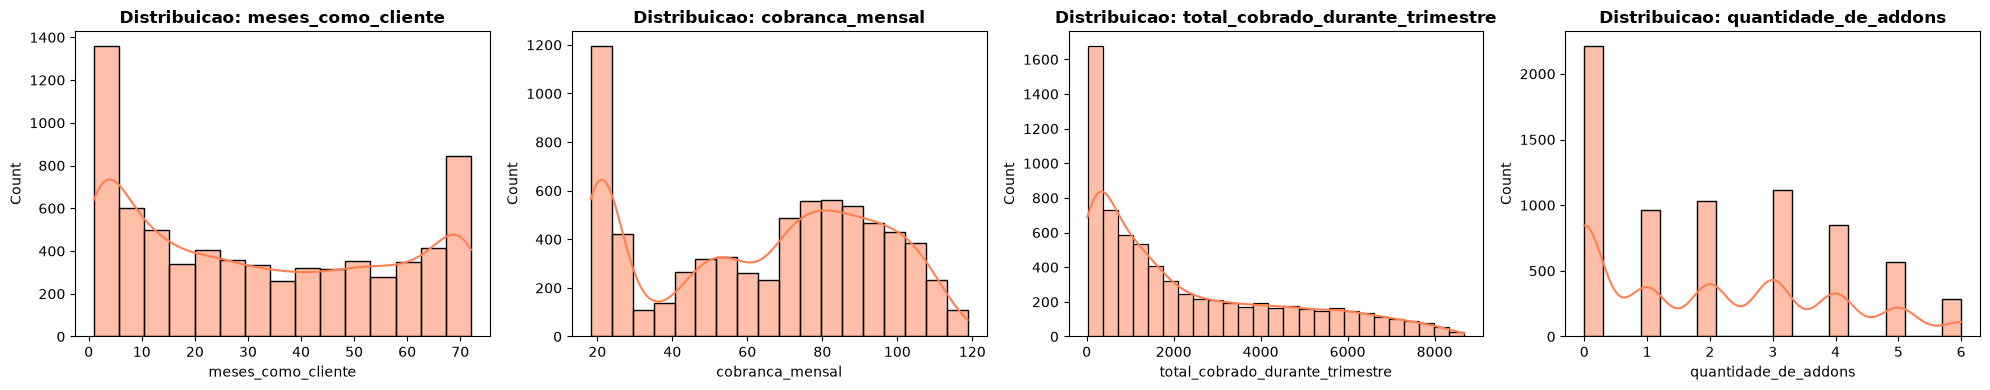

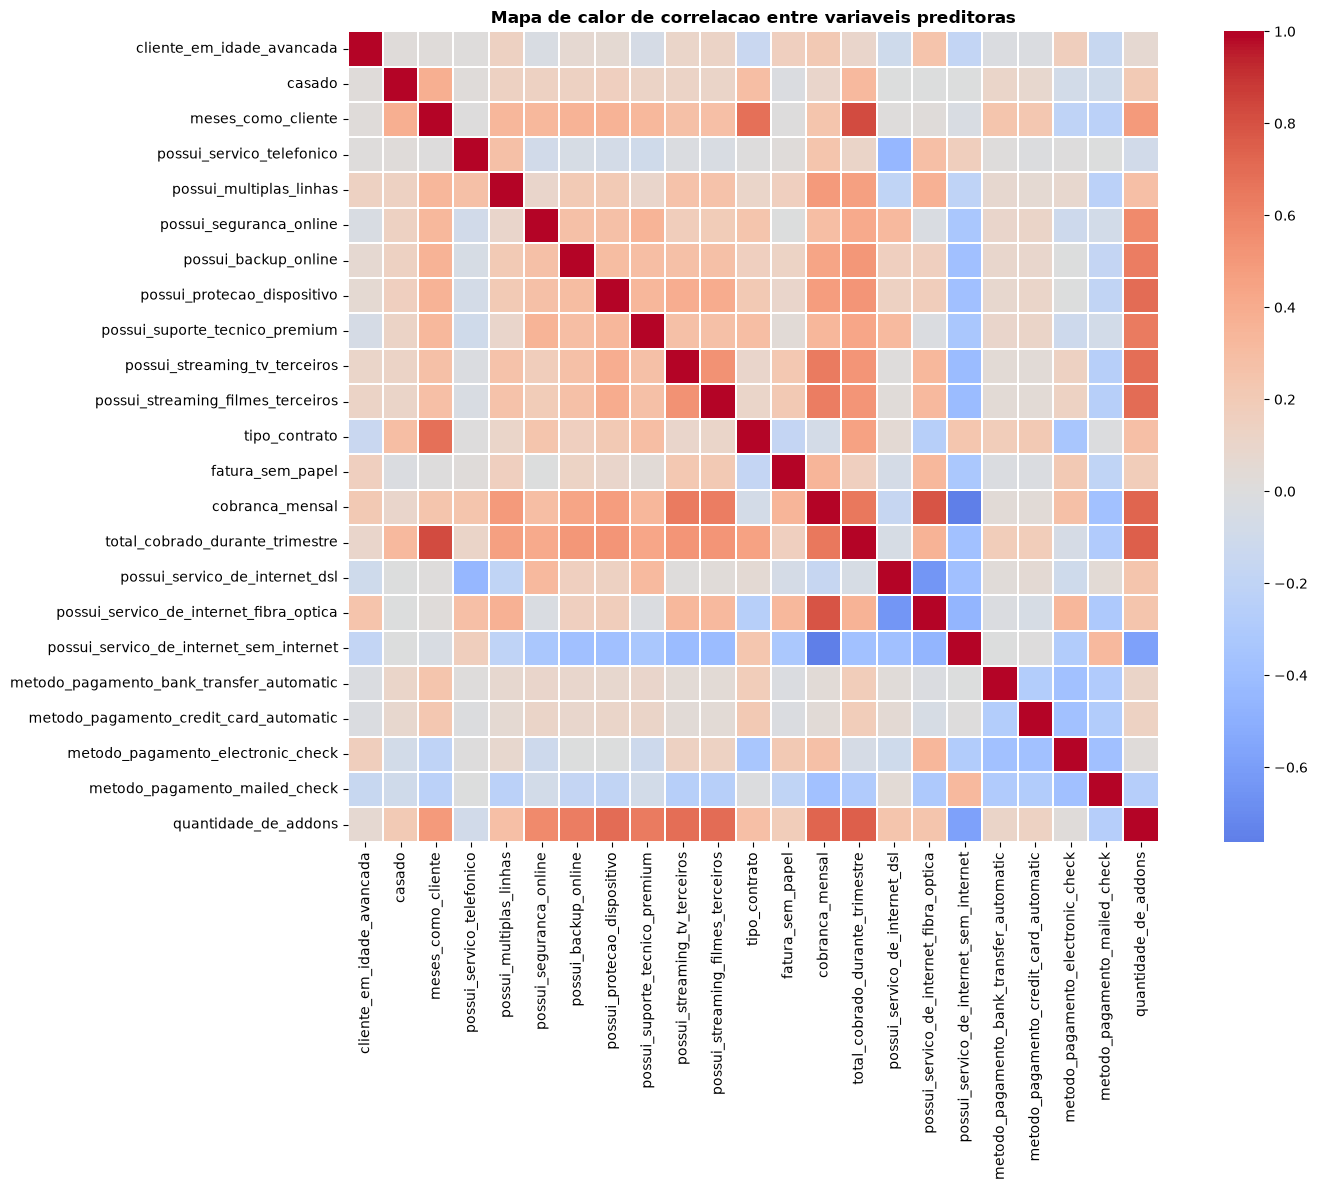

Pares de features preditoras com |correlacao| >= 0.5:
                              feature_1                               feature_2  correlacao
                     meses_como_cliente         total_cobrado_durante_trimestre       0.826
                        cobranca_mensal possui_servico_de_internet_fibra_optica       0.787
                        cobranca_mensal possui_servico_de_internet_sem_internet      -0.763
        total_cobrado_durante_trimestre                    quantidade_de_addons       0.746
                        cobranca_mensal                    quantidade_de_addons       0.725
            possui_protecao_dispositivo                    quantidade_de_addons       0.693
      possui_streaming_filmes_terceiros                    quantidade_de_addons       0.693
          possui_streaming_tv_terceiros                    quantidade_de_addons       0.688
                     meses_como_cliente                           tipo_contrato       0.677
                        co

In [13]:
colunas_numericas_para_distribuicao = ["meses_como_cliente", "cobranca_mensal", "total_cobrado_durante_trimestre", "quantidade_de_addons"]

tabela_alta_correlacao = exibir_distribuicao_e_correlacao(
    dataframe_de_churn_missing_values_aplicado,
    colunas_numericas_para_distribuicao,
)


## Removendo feature redundante por alta colinearidade

In [14]:
dataframe_de_churn_missing_values_aplicado = remover_colunas(
    dataframe_de_churn_missing_values_aplicado,
    ["total_cobrado_durante_trimestre"],
)

dataframe_de_churn_missing_values_aplicado.head(n=100)


,cliente_em_idade_avancada,casado,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,cobranca_mensal,target,possui_servico_de_internet_dsl,possui_servico_de_internet_fibra_optica,possui_servico_de_internet_sem_internet,metodo_pagamento_bank_transfer_automatic,metodo_pagamento_credit_card_automatic,metodo_pagamento_electronic_check,metodo_pagamento_mailed_check,quantidade_de_addons
0,0,1,1,0,0,0,1,0,0,0,0,0,1,29.85,0,1,0,0,0,0,1,0,1
1,0,0,34,1,0,1,0,1,0,0,0,1,0,56.95,0,1,0,0,0,0,0,1,2
2,0,0,2,1,0,1,1,0,0,0,0,0,1,53.85,1,1,0,0,0,0,0,1,2
3,0,0,45,0,0,1,0,1,1,0,0,1,0,42.30,0,1,0,0,1,0,0,0,3
4,0,0,2,1,0,0,0,0,0,0,0,0,1,70.70,1,0,1,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0,0,12,1,1,1,0,0,0,0,0,0,1,78.95,1,0,1,0,0,0,1,0,1
96,0,1,71,1,1,1,1,0,1,0,0,1,1,66.85,0,1,0,0,0,1,0,0,3
97,0,0,5,1,0,0,0,0,0,0,0,0,0,21.05,1,0,0,1,0,0,0,1,0
98,0,0,52,1,0,0,0,0,0,0,0,2,0,21.00,0,0,0,1,1,0,0,0,0


## Removendo linhas duplicadas

In [15]:
dataframe_de_churn_missing_values_aplicado = remover_duplicatas(
    dataframe_de_churn_missing_values_aplicado
)

dataframe_de_churn_missing_values_aplicado.head(n=100)


Linhas duplicadas encontradas: 73
Registros antes: 7032, Registros depois: 6959, Registros removidos: 73


,cliente_em_idade_avancada,casado,meses_como_cliente,possui_servico_telefonico,possui_multiplas_linhas,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,cobranca_mensal,target,possui_servico_de_internet_dsl,possui_servico_de_internet_fibra_optica,possui_servico_de_internet_sem_internet,metodo_pagamento_bank_transfer_automatic,metodo_pagamento_credit_card_automatic,metodo_pagamento_electronic_check,metodo_pagamento_mailed_check,quantidade_de_addons
0,0,1,1,0,0,0,1,0,0,0,0,0,1,29.85,0,1,0,0,0,0,1,0,1
1,0,0,34,1,0,1,0,1,0,0,0,1,0,56.95,0,1,0,0,0,0,0,1,2
2,0,0,2,1,0,1,1,0,0,0,0,0,1,53.85,1,1,0,0,0,0,0,1,2
3,0,0,45,0,0,1,0,1,1,0,0,1,0,42.30,0,1,0,0,1,0,0,0,3
4,0,0,2,1,0,0,0,0,0,0,0,0,1,70.70,1,0,1,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0,0,12,1,1,1,0,0,0,0,0,0,1,78.95,1,0,1,0,0,0,1,0,1
96,0,1,71,1,1,1,1,0,1,0,0,1,1,66.85,0,1,0,0,0,1,0,0,3
97,0,0,5,1,0,0,0,0,0,0,0,0,0,21.05,1,0,0,1,0,0,0,1,0
98,0,0,52,1,0,0,0,0,0,0,0,2,0,21.00,0,0,0,1,1,0,0,0,0


## Proporcao da variavel target

=== DISTRIBUICAO DA VARIAVEL TARGET ===

Contagem:
target
0    5117
1    1842
Name: count, dtype: int64

Percentual:
Nao cancelou (0): 73.53%
Cancelou (1): 26.47%


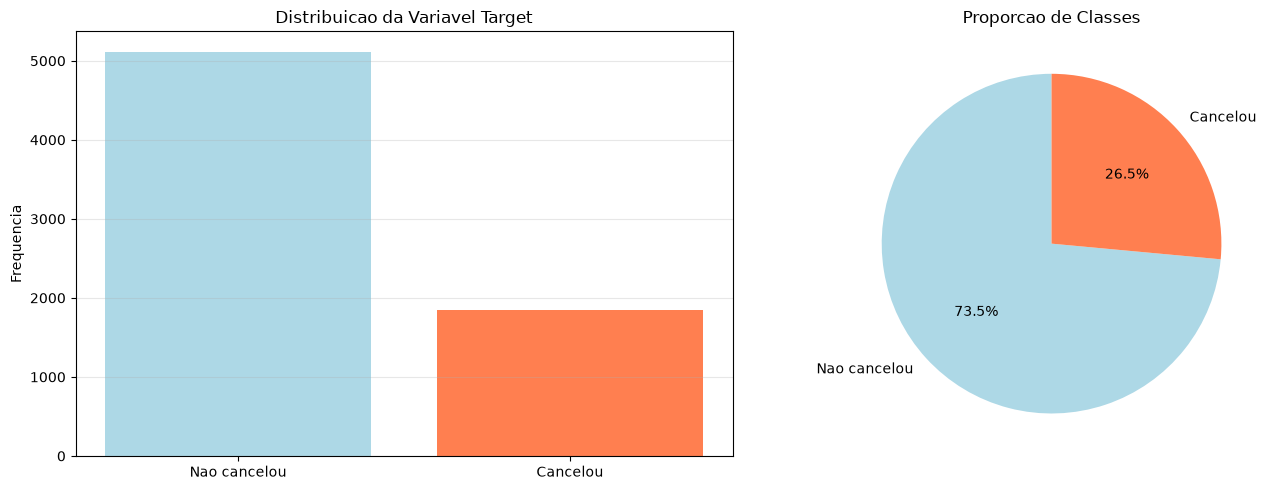


Ratio de balanceamento: 0.36
Dataset desbalanceado! Considere usar tecnicas como SMOTE ou class_weight.


In [16]:
textos_desbalanceado = [
    "Dataset desbalanceado! Considere usar tecnicas como SMOTE ou class_weight.",
]
texto_balanceado = "Dataset razoavelmente balanceado."

exibir_proporcao_target(
    dataframe_de_churn_missing_values_aplicado,
    textos_desbalanceado,
    texto_balanceado,
)


## Analise de dispersao das variaveis numericas em relacao a media

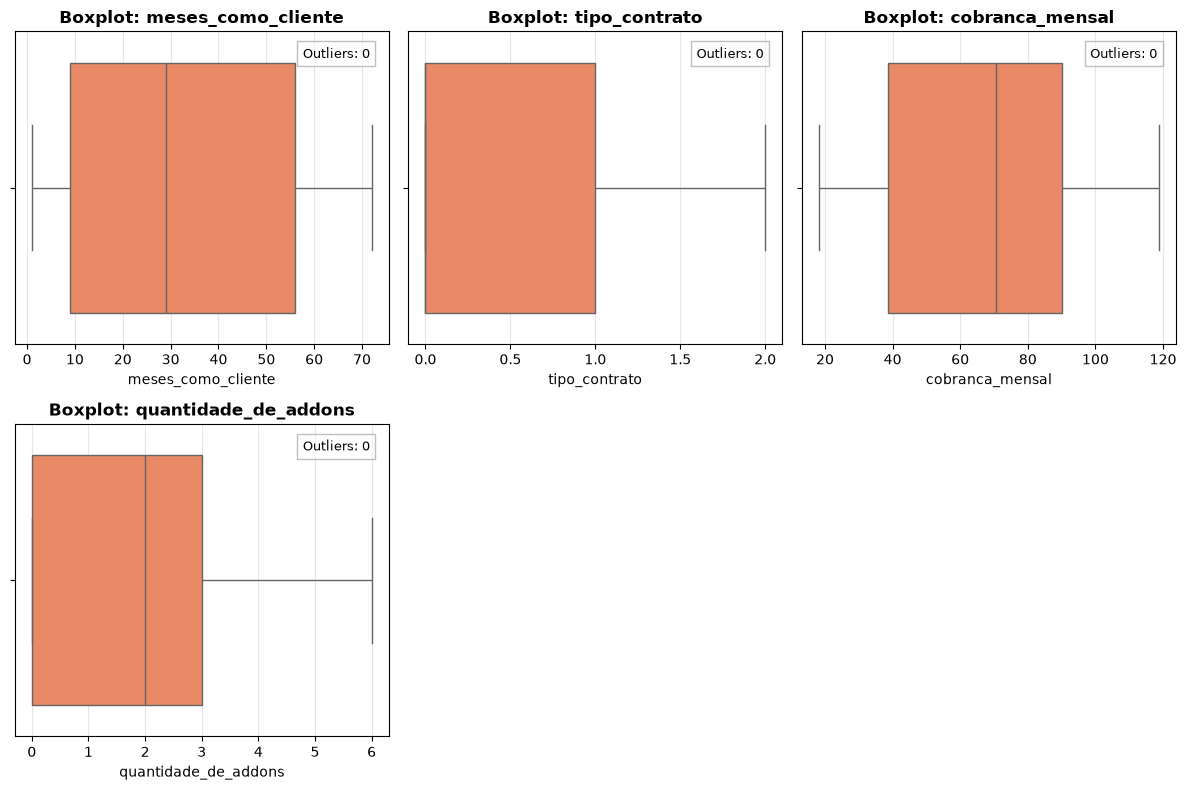

In [17]:
numeric_cols = ["meses_como_cliente", "tipo_contrato", "cobranca_mensal", "quantidade_de_addons"]

exibir_dispersao(dataframe_de_churn_missing_values_aplicado, numeric_cols)


## Informacoes Estatisticas

In [18]:
colunas_para_describe = ["meses_como_cliente", "tipo_contrato", "cobranca_mensal", "quantidade_de_addons"]

descrever_colunas(dataframe_de_churn_missing_values_aplicado, colunas_para_describe)


,meses_como_cliente,tipo_contrato,cobranca_mensal,quantidade_de_addons
count,6959.00,6959.00,6959.00,6959.00
mean,32.62,0.69,65.11,2.06
std,24.46,0.83,29.97,1.84
min,1.00,0.00,18.25,0.00
25%,9.00,0.00,38.50,0.00
50%,29.00,0.00,70.55,2.00
75%,56.00,1.00,89.98,3.00
max,72.00,2.00,118.75,6.00


## Dividindo dados entre treino e teste

In [19]:
X, y, X_train, X_test, y_train, y_test = dividir_treino_teste(
    dataframe_de_churn_missing_values_aplicado,
    test_size=0.3,
    random_state=42,
    estratificar=True,
)


X_train: (4871, 22), X_test: (2088, 22), y_train: (4871,), y_test: (2088,)


## Persistindo a base final de treinamento em joblib (versionada no DVC)

In [20]:
dados_processados_dir = Path(PROJETO_RAIZ / "data" / "processed" / "regressao_losgistica")
dados_processados_dir.mkdir(parents=True, exist_ok=True)

caminho_base_treinamento = dados_processados_dir / "dataframe_de_churn_missing_values_aplicado.joblib"
joblib.dump(dataframe_de_churn_missing_values_aplicado, caminho_base_treinamento)

print(f"Base final de treinamento salva em: {caminho_base_treinamento}")
print(f"Shape: {dataframe_de_churn_missing_values_aplicado.shape}")

resultado_dvc_add = subprocess.run(
    ["dvc", "add", str(caminho_base_treinamento)],
    cwd=PROJETO_RAIZ,
    capture_output=True, text=True
)
print(resultado_dvc_add.stdout)
print(resultado_dvc_add.stderr)

Base final de treinamento salva em: C:\Projetos\FIAP\Fase_1\Tech_Challenge_Churn_Prediction\data\processed\regressao_losgistica\dataframe_de_churn_missing_values_aplicado.joblib
Shape: (6959, 23)



To track the changes with git, run:

	git add 'data\processed\regressao_losgistica\dataframe_de_churn_missing_values_aplicado.joblib.dvc'

To enable auto staging, run:

	dvc config core.autostage true

\u280b Checking graph




## Engenharia de features: faixa de meses (1 a 12) com target encoding

`meses_como_cliente` e trocado pela taxa de churn da faixa (12 faixas de 6 meses). A taxa e aprendida somente com o treino e aplicada ao teste, evitando vazamento do target.

In [21]:
X_train, X_test, taxa_de_churn_por_faixa = aplicar_target_encoding_faixa_de_meses(X_train, X_test, y_train)

taxa_de_churn_por_faixa.round(3)

meses_como_cliente
1     0.530
2     0.365
3     0.333
4     0.258
5     0.208
6     0.199
7     0.218
8     0.165
9     0.185
10    0.129
11    0.099
12    0.051
Name: target, dtype: float64

## Redimensionando a escala dos dados antes do treino

In [22]:
colunas_para_escalonar = ["faixa_meses_target_encoding", "tipo_contrato", "cobranca_mensal", "quantidade_de_addons"]
X_train_escalonado, X_test_escalonado, escalonador = escalonar_colunas(
    X_train, X_test, colunas_para_escalonar
)
X_train_escalonado.head(n=100)

,cliente_em_idade_avancada,casado,possui_servico_telefonico,possui_multiplas_linhas,possui_seguranca_online,possui_backup_online,possui_protecao_dispositivo,possui_suporte_tecnico_premium,possui_streaming_tv_terceiros,possui_streaming_filmes_terceiros,tipo_contrato,fatura_sem_papel,cobranca_mensal,possui_servico_de_internet_dsl,possui_servico_de_internet_fibra_optica,possui_servico_de_internet_sem_internet,metodo_pagamento_bank_transfer_automatic,metodo_pagamento_credit_card_automatic,metodo_pagamento_electronic_check,metodo_pagamento_mailed_check,quantidade_de_addons,faixa_meses_target_encoding
401,0,0,1,0,0,0,0,0,0,0,0.376981,0,-1.501215,0,0,1,0,1,0,0,-1.108116,0.621871
6440,0,0,1,1,0,0,1,0,1,1,-0.827134,1,1.203069,0,1,0,0,0,1,0,0.508587,-0.405305
4824,1,1,1,1,0,1,0,0,1,1,0.376981,1,1.066691,0,1,0,0,1,0,0,0.508587,-1.322871
2099,0,1,1,1,0,0,0,1,0,0,-0.827134,1,0.454651,0,1,0,0,1,0,0,-0.569215,-0.287197
3378,0,1,1,0,1,1,1,1,1,1,1.581097,0,0.640924,1,0,0,0,0,0,1,2.125290,-1.322871
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6775,1,0,1,1,0,1,1,0,1,1,1.581097,1,0.484588,1,0,0,1,0,0,0,1.047488,-0.842978
2244,0,0,1,1,1,1,0,1,0,0,0.376981,1,-0.026000,1,0,0,0,0,0,1,0.508587,-0.405305
1974,0,1,1,1,0,0,0,0,0,0,-0.827134,1,0.324925,0,1,0,0,0,1,0,-1.108116,0.621871
5127,0,0,1,1,1,1,1,1,1,1,0.376981,1,1.768541,0,1,0,1,0,0,0,2.125290,-1.322871


## Aplicando SMOTE para balanceamento entre as classes

In [23]:
X_train_balanceado, y_train_balanceado, smote = aplicar_smote(X_train_escalonado, y_train)


Distribuicao antes do SMOTE:
target
0    3582
1    1289
Name: count, dtype: int64

Distribuicao depois do SMOTE:
target
0    3582
1    3582
Name: count, dtype: int64


## Validacao cruzada estratificada (K-Fold) para avaliar robustez do modelo

In [24]:
tabela_metricas_cv = validar_em_kfold(
    X,
    y,
    {
        "regressao_logistica": lambda: LogisticRegression(penalty="l1", solver="liblinear", C=1.0, random_state=42, max_iter=2000),
    },
    n_splits=5,
    random_state=42,
    preparar_treino=preparar_treino_com_faixa_escala_e_smote(colunas_para_escalonar),
    grafico=None,
)


C:\Projetos\FIAP\Fase_1\Tech_Challenge_Churn_Prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Projetos\FIAP\Fase_1\Tech_Challenge_Churn_Prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


C:\Projetos\FIAP\Fase_1\Tech_Challenge_Churn_Prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Projetos\FIAP\Fase_1\Tech_Challenge_Churn_Prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


C:\Projetos\FIAP\Fase_1\Tech_Challenge_Churn_Prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Projetos\FIAP\Fase_1\Tech_Challenge_Churn_Prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


C:\Projetos\FIAP\Fase_1\Tech_Challenge_Churn_Prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Projetos\FIAP\Fase_1\Tech_Challenge_Churn_Prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


C:\Projetos\FIAP\Fase_1\Tech_Challenge_Churn_Prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Projetos\FIAP\Fase_1\Tech_Challenge_Churn_Prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


Metricas por fold:
 fold  acuracia  precisao  recall  f1_score  roc_auc
    1    0.7967    0.5934  0.7337    0.6561   0.8524
    2    0.7730    0.5556  0.7065    0.6220   0.8294
    3    0.7773    0.5637  0.7073    0.6274   0.8502
    4    0.7787    0.5688  0.6829    0.6207   0.8421
    5    0.7779    0.5634  0.7120    0.6291   0.8364

Media +/- desvio padrao entre os 5 folds:
acuracia: 0.7807 +/- 0.0092
precisao: 0.5690 +/- 0.0145
recall: 0.7085 +/- 0.0181
f1_score: 0.6311 +/- 0.0145
roc_auc: 0.8421 +/- 0.0096


## Treinamento do modelo com SMOTE, selecao de features via Lasso (L1) e registro de metricas no DVC

C:\Projetos\FIAP\Fase_1\Tech_Challenge_Churn_Prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Projetos\FIAP\Fase_1\Tech_Challenge_Churn_Prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


Features zeradas pelo Lasso (1): ['possui_servico_de_internet_sem_internet']

Coeficientes ordenados por magnitude:
quantidade_de_addons                        11.840222
possui_seguranca_online                     -7.332622
possui_suporte_tecnico_premium              -7.306310
possui_backup_online                        -6.814579
possui_protecao_dispositivo                 -6.763175
possui_streaming_tv_terceiros               -6.685524
possui_streaming_filmes_terceiros           -6.672261
metodo_pagamento_credit_card_automatic      -4.924256
metodo_pagamento_bank_transfer_automatic    -4.799832
metodo_pagamento_mailed_check               -4.747092
metodo_pagamento_electronic_check           -4.243639
cobranca_mensal                              2.118713
possui_servico_de_internet_fibra_optica     -1.872824
possui_servico_telefonico                   -1.739626
possui_servico_de_internet_dsl              -1.243967
faixa_meses_target_encoding                  0.760485
tipo_contrato       

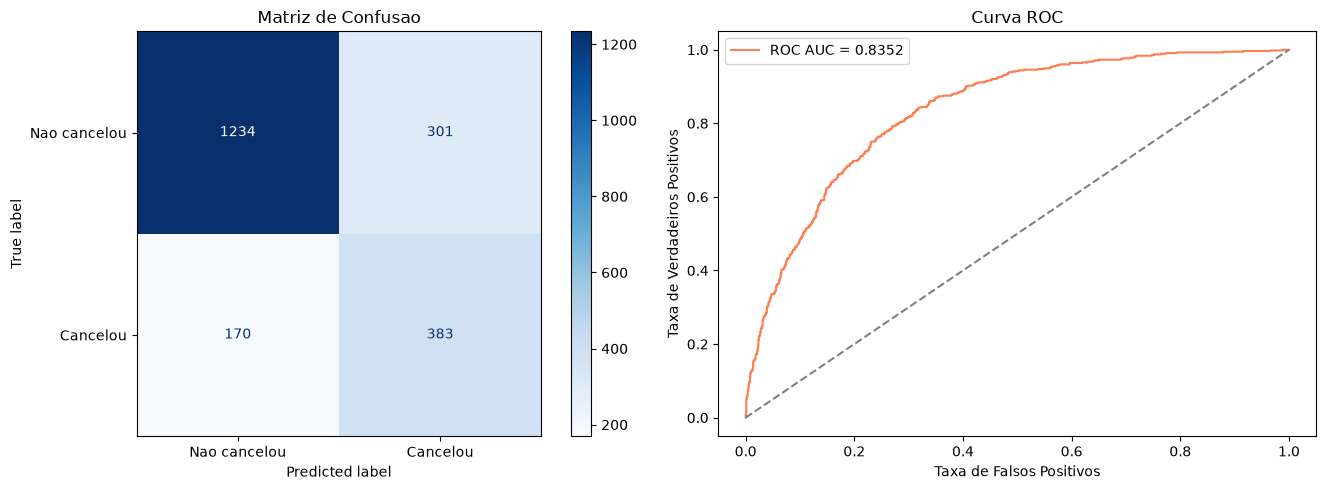

Path                                                                           acuracia    acuracia_cv_desvio    acuracia_cv_media    ccp_alpha_utilizado    class_weight_utilizado    cv_treino.acuracia.desvio    cv_treino.acuracia.media    cv_treino.f1_score.desvio    cv_treino.f1_score.media    cv_treino.precisao.desvio    cv_treino.precisao.media    cv_treino.recall.desvio    cv_treino.recall.media    cv_treino.roc_auc.desvio    cv_treino.roc_auc.media    f1_score    f1_score_cv_desvio    f1_score_cv_media    learning_rate_utilizado    max_depth_utilizado    melhores_parametros.mlp__alpha    melhores_parametros.mlp__learning_rate_init    min_samples_leaf_utilizado    min_samples_split_utilizado    n_estimators_utilizado    peso_classe_1_sample_weight    pesos_por_classe.0    pesos_por_classe.1    precisao    precisao_cv_desvio    precisao_cv_media    premissas_custo.custo_de_um_contato    premissas_custo.meses_de_receita_perdida    recall    recall_cv_desvio    recall_cv_media    roc

In [25]:
modelo_regressao_logistica = LogisticRegression(penalty="l1", solver="liblinear", C=1.0, random_state=42, max_iter=2000)
modelo_regressao_logistica.fit(X_train_balanceado, y_train_balanceado)

coeficientes_lasso = pd.Series(modelo_regressao_logistica.coef_[0], index=X_train_balanceado.columns)
features_zeradas_pelo_lasso = coeficientes_lasso[coeficientes_lasso == 0].index.tolist()
print(f"Features zeradas pelo Lasso ({len(features_zeradas_pelo_lasso)}): {features_zeradas_pelo_lasso}")
print("\nCoeficientes ordenados por magnitude:")
print(coeficientes_lasso.reindex(coeficientes_lasso.abs().sort_values(ascending=False).index))

y_pred = modelo_regressao_logistica.predict(X_test_escalonado)
y_proba = modelo_regressao_logistica.predict_proba(X_test_escalonado)[:, 1]

metricas_calculadas = calcular_metricas_classificacao(y_test, y_pred, y_proba)
acuracia = metricas_calculadas["acuracia"]
precisao = metricas_calculadas["precisao"]
recall = metricas_calculadas["recall"]
f1 = metricas_calculadas["f1_score"]
matriz_confusao = metricas_calculadas["matriz_confusao"]
fpr = metricas_calculadas["fpr"]
tpr = metricas_calculadas["tpr"]
roc_auc = metricas_calculadas["roc_auc"]

exibir_metricas_classificacao(acuracia, precisao, recall, f1, roc_auc, matriz_confusao, prefixo="\n")

metricas_dir = Path(PROJETO_RAIZ / "notebooks" / "regressao_logistica" / "historico" / "metrics")
metricas = {
    "acuracia": acuracia,
    "precisao": precisao,
    "recall": recall,
    "f1_score": f1,
    "roc_auc": roc_auc,
    "features_zeradas_pelo_lasso": features_zeradas_pelo_lasso,
    "matriz_confusao": matriz_confusao.tolist(),
}

salvar_metricas(metricas, metricas_dir)

exibir_matriz_e_roc(matriz_confusao, fpr, tpr, roc_auc)

resultado_dvc = consultar_metricas_dvc(PROJETO_RAIZ)
